# Lab 6: Interpolation

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

6.1  <font color='red'>     **Activity: Linear Interpolation** </font>
    
1.  In an Jupyter-notebook, explore the behaviour of the Linear Interpolation algorithm when varying the number of data used.
2.  Construya la interpolación lineal para la función $f(x)=x^3$ en $x\, ϵ\, [-9,9]$
- - -

In [ ]:
def LinearInterpolator(x, Xn, Yn):
    Yn = np.array(Yn)
    Xn = np.array(Xn)
    x = np.atleast_1d(x).astype(float).flatten()

    Yn = Yn[np.argsort(Xn)]
    Xn = Xn[np.argsort(Xn)]

    Ninter = len(x)

    term = lambda x, i: (Yn[i+1] - Yn[i])/(Xn[i+1] - Xn[i])*(x - Xn[i]) + Yn[i]

    y = []
    for n in range(Ninter):
        for i in range(len(Xn)):
            if x[n] <= Xn[i]:
                break
        y.append(term(x[n], i-1))

    return np.array(y)

In [ ]:
def fun(x):
  return x**3
xn = np.linspace(-9,9,100)
yn = fun(xn)
len(fun(xn))

100

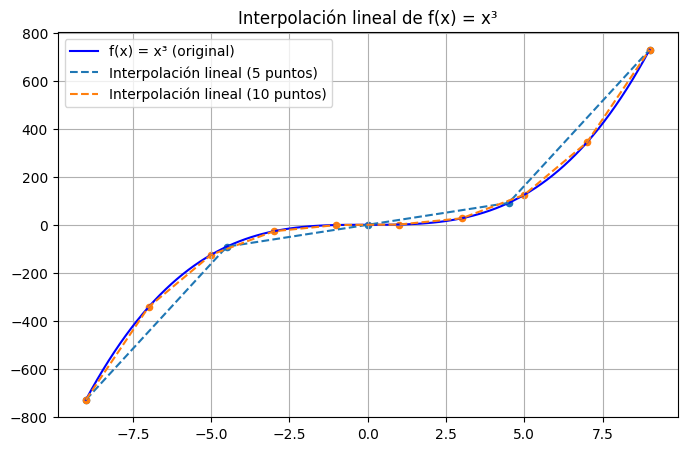

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(xn, yn, label="f(x) = x³ (original)", color="blue")
for n in [5, 10]:
    Xn2 = np.linspace(-9, 9, n)
    Yn = fun(Xn2)
    LinearInterpolator(xn, Xn2, Yn)

    plt.plot(xn, LinearInterpolator(xn, Xn2, Yn), label=f'Interpolación lineal ({n} puntos)', linestyle='--')
    plt.scatter(Xn2, Yn, s=20)
plt.title("Interpolación lineal de f(x) = x³")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
P1 = 20

6.2 <font color='red'>     **Activity: Lagrange Interpolation** </font>

  Write your own implementation or see the Lagrange interpolation algorithm done during classtime.
- - -

In [ ]:
def Lagrange(xn,I):
  n = len(xn)
  x = sp.Symbol("x")
  l = 1
  for i in range(n):
    if xn[i] != xn[I]:
      pr =  (x-xn[i])/(xn[I]-xn[i])
      l *= pr
  return l
def pn(xn,yn):
  n = len(xn)
  pn = 0
  for i in range(n):
    pn += yn[i]*Lagrange(xn,i)
  return (pn.expand(pn))

In [ ]:
xn = [0,1,2]
yn = [0,1,8]
x = sp.Symbol("x")
pn(xn,yn)


3*x**2 - 2*x

6.3 <font color='red'>     **Activity** </font> LP

<div style="float: right;" markdown="1">
    <img src="http://universe-review.ca/I05-28-NGC7331.jpg">
</div>

One of the very first evidences of the existence of dark matter was the flat rotation curves of spiral galaxies. If we assume the total budget of mass of a galaxy is entirely made of luminous matter, the orbital circular velocity of stars around the galaxy plane should decay according to a keplerian potential. However this is not the case and the circular velocity barely decreases at larger radius, thus indicating the presence of a new non-visible matter component (dark matter). When it is necessary to determine how massive is the dark matter halo embedding a galaxy, an integration of the circular velocity is required. Nevertheless, due to the finite array of a CCD camera, only a discrete set of velocities can be measured and interpolation techniques are required.


In this activity we will take a discrete dataset of the circular velocity as a function of the radius for the galaxy [NGC 7331](http://es.wikipedia.org/wiki/NGC_7331) and perform both, a linear and a Lagrange interpolation. You can download the dataset from this [link](https://raw.githubusercontent.com/sbustamante/ComputationalMethods/master/data/NGC7331.dat).


In [ ]:
url = 'https://raw.githubusercontent.com/sbustamante/ComputationalMethods/master/data/NGC7331.dat'
df = pd.read_table(url, sep="\s+", header=None)
df.columns = ["radio","vel"]

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipython-input-648573360.py:2: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_table(url, sep="\s+", header=None)


In [ ]:
radio = df["radio"]
velocidad = df["vel"]
indice = (np.arange(2,600,50))
radio_l = []
velocidad_l =[]
for i in indice:
  radio_l.append(radio[i])
  velocidad_l.append(velocidad[i])

In [ ]:
interpolacion_lagrage = pn(radio_l, velocidad_l)

Text(0.5, 1.0, 'interpolacion normal')

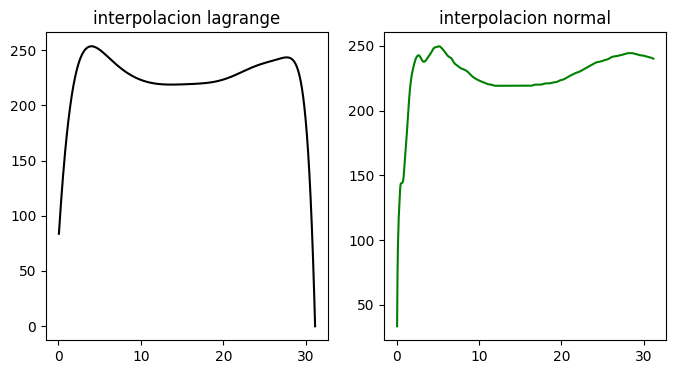

In [ ]:
from scipy.interpolate import lagrange
radio = df["radio"]
velocidad = df["vel"]
interpolacion_lagrage = lagrange(radio_l, velocidad_l)
interpolacion_normal = LinearInterpolator(radio,radio,velocidad)
fig, ax = plt.subplots(1,2,figsize = (8,4))
ax[0].plot(radio,interpolacion_lagrage(radio), color = "black")
ax[1].plot(radio,interpolacion_normal, color = "green")
ax[0].set_title("interpolacion lagrange")
ax[1].set_title("interpolacion normal")

In [ ]:
P3 = 15
#lagrange no se ve muy bien.

next class

6.4 <font color='red'>     **Activity: Divided difference** </font>
1.  Using the previous expression and the defined function for divided differences construc the $P_2(x)$ for $f(x)=x^3$, $x ϵ [0,2]$ given the three points $[0,1,2]=[x_0,x_1,x_2]$.
2.  Construc the $P_4(x)$ for $f(x)=x^3$, $x_i = [0,2]$ given the 5 points $[0,0.5,1,1.5,2]$.
3.  Show both methods to calculate Lagrange interpolators are equivalents (opcional)...

In [ ]:
def D( i, k, Xn, Yn ):
    if i+k>=len(Xn):
        return 0
    elif k == 0:
        return Yn[i]
    else:
        return (D(i+1, k-1, Xn, Yn)-D(i, k-1, Xn, Yn))/(Xn[i+k]-Xn[i])

In [ ]:
xn = [0,1,2]
yn = lambda x: x**3
def evaluar_f(f,lista):
  resultado = []
  for i in lista:
    resultado.append(f(i))
  return resultado
coeficientes = []
for i in range(len(xn)):
  coeficientes.append(D(0,i,xn,evaluar_f(yn,xn)))
pn2 = int(coeficientes[0])+int(coeficientes[1])*(x-xn[0])+int(coeficientes[2])*(x-xn[0])*(x-xn[1])
print(pn2.expand())
pn2.expand()
pn(xn,evaluar_f(yn,xn))

3*x**2 - 2*x


3*x**2 - 2*x

In [ ]:
xn = np.linspace(0,2,4)
yn = [0,0.5,1,1.5,2]
coeficientes2 = []
for i in range(5):
  coeficientes2.append(D(0,i,xn,yn))
pn4 = (coeficientes2[0])+(coeficientes2[1])*(x-xn[0])+(coeficientes2[2])*(x-xn[0])*(x-xn[1])+(coeficientes2[3])*(x-xn[0])*(x-xn[1])*(x-xn[2])+(coeficientes2[4])*(x-xn[0])*(x-xn[1])*(x-xn[2])*(x-xn[3])
print(pn4.expand())
pn(xn,yn)

-4.16333634234434e-17*x**3 + 8.32667268468867e-17*x**2 + 0.75*x


6.66133814775094e-16*x**2 + 0.75*x

Se puede ver que los coeficientes de x son iguales y como los otros son sumamente pequeños, esto lo podemos aproximar a cero por lo pequeño que resulta, obteniendo en ambos casos, solo el valor de X en ambos polinomios, osea podemos redondear y concluir que ambos son iguales

Se puede ver como los

In [ ]:
P4 = 15 #falto P4

6.5  <font color='red'> **Activity: Hermite Polynomial** </font>

<font color='red'>    

Calculate a routine, using the previous program for divided differences, that computes the Hermite polynomial given a dataset.

Generate a set of $N$ points of the function $\sin^2(x)$ between $0$ and $2\pi$, including an array of $x$ positions, $y = f(x)$ and first derivative $y' = f'(x)$.

Show which polynomial gives the best approximation to the real function, Hermite or Lagrange polynomial.

</font>

<font color='white'>
Solution:

nbviewer.ipython.org/github/sbustamante/ComputationalMethods/blob/master/activities/hermite-and-lagrange.ipynb
</font>

In [ ]:
f = lambda x: np.sin(x)**2
g = lambda x: 2*np.sin(x)*np.cos(x)

N = 5
x = np.linspace(0, 2*np.pi, N)
y = f(x)
yp = g(x)

def Dh( j, k, Zn, Yn, Ypn ):
    if j+k>=len(Zn):
        return 0
    elif k == 0:
        return Yn[int(j/2)]
    elif k == 1 and j%2 == 0:
        return Ypn[int(j/2)]
    else:
        return (Dh(j+1, k-1, Zn, Yn, Ypn)-Dh(j, k-1, Zn, Yn, Ypn))/(Zn[j+k]-Zn[j])
def Hermite(Zn, Yn, Ypn, x ):
  b,c=1,0
  a = Dh( 0, 0, Zn, Yn, Ypn )

  for k in range(1,len(Zn)-1):
    b *= (x-Zn[k-1])
    c += Dh( 0, k, Zn, Yn, Ypn )*b
  return a+c
Zn = np.repeat(x, 2)

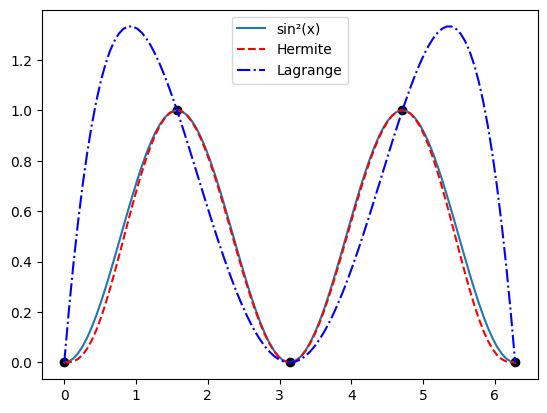

In [ ]:
L = lagrange(x, y)

puntos = np.linspace(0, 2*np.pi, 100)
plt.plot(puntos, f(puntos), label='sin²(x)')
plt.plot(puntos, [Hermite(Zn,y,yp,x_i) for x_i in puntos],'r--', label='Hermite')
plt.plot(puntos, L(puntos), 'b-.', label='Lagrange')
plt.scatter(x, y, color='black')
plt.legend()
plt.show()

In [ ]:
#Lagrange parece tener un error. no es tan malo
P5 = 18

In [ ]:
puntos = (P1 + P3 + P4 + P5)*(5/4)
nota = puntos*5/100
print('puntos:', puntos,'nota=', nota)

puntos: 85.0 nota= 4.25
